In [1]:
import pandas as pd
import numpy as np

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
np.set_printoptions(suppress=True, precision=6)

In [4]:
# ignore warnings for cleaner output
import warnings
warnings.filterwarnings("ignore")
# ignore ConvergenceWarning
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

In [5]:
pd.set_option('display.float_format', '{:.2f}'.format)

In [6]:
raw_df = pd.read_csv('./content/combined_dataset.csv')

In [7]:
raw_df.shape

(229533, 14)

In [8]:
raw_df.isnull().sum() 

HHID                     0
TotalAssets              0
TotalIncome              0
EducationLevel           0
AgeOfHeadSq              0
isFemaleHead             0
HouseholdSize            0
isRural                  0
LoanTenureInYears        0
isST                     0
isSC                     0
isOBC                    0
isGeneral                0
MaxAnnualInterestRate    0
dtype: int64

In [9]:
df = raw_df[
    (raw_df['TotalIncome'] > 0.0) &
    (raw_df['TotalAssets'] >= 0.0) &
    (raw_df['HouseholdSize'] > 0) &
    (raw_df['LoanTenureInYears'] >= 0) &
    (raw_df['MaxAnnualInterestRate'] >= 0.0) &
    (raw_df['AgeOfHeadSq'] > 0) &
    (raw_df[['isST', 'isSC', 'isOBC', 'isGeneral']].sum(axis=1) == 1)
]


In [10]:
df.shape

(116097, 14)

In [11]:
# find average HouseholdSize
df['HouseholdSize'].mean()

np.float64(4.265226491640611)

# Bin Economic Outcomes (low, med, high incomes)

In [12]:
df['IncomePerCapita'] = df['TotalIncome']/df['HouseholdSize']

In [13]:
df.head()[['IncomePerCapita', 'TotalIncome', 'HouseholdSize']]


,IncomePerCapita,TotalIncome,HouseholdSize
0,3000.00,15000.00,5
1,3000.00,12000.00,4
2,3250.00,6500.00,2
3,3000.00,15000.00,5
4,3000.00,15000.00,5


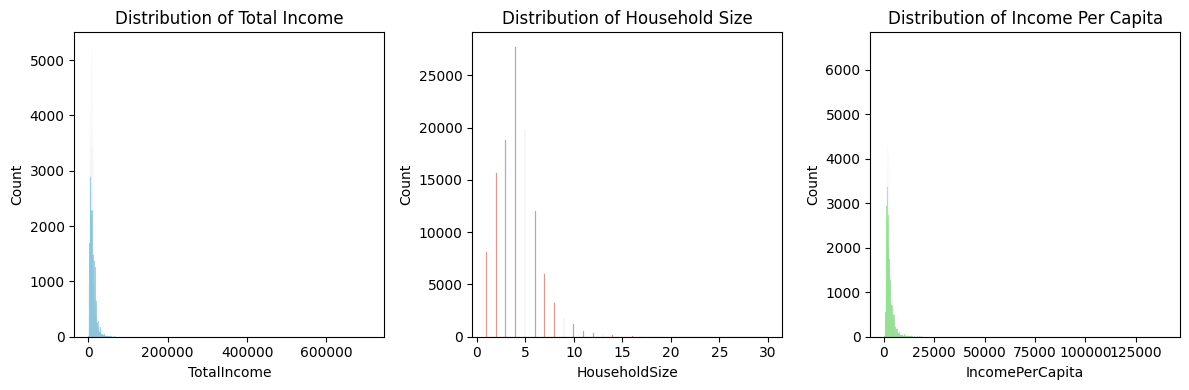

In [14]:
# plot there distribution of total income, household size, and income per capita
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
sns.histplot(df['TotalIncome'], bins="auto", ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Total Income')
sns.histplot(df['HouseholdSize'], bins="auto", ax=axes[1], color='salmon')
axes[1].set_title('Distribution of Household Size')
sns.histplot(df['IncomePerCapita'], bins="auto", ax=axes[2], color='lightgreen')
axes[2].set_title('Distribution of Income Per Capita')
plt.tight_layout()
plt.show()

In [15]:
# show max and min of IncomePerCapita, TotalIncome, HouseholdSize
df[['IncomePerCapita', 'TotalIncome', 'HouseholdSize']].agg(['min', 'max'])

,IncomePerCapita,TotalIncome,HouseholdSize
min,175.00,300.00,1
max,140000.00,710000.00,30


In [16]:
# Define monthly income bins and labels
bins = [0, 11574, 69444, float('inf')]
labels = ['Low_Income', 'Mid_Income', 'High_Income']

# Apply categorization
df['IncomeState'] = pd.cut(df['IncomePerCapita'], bins=bins, labels=labels, right=False)

In [17]:
# count number of entries in each category
df['IncomeState'].value_counts()

IncomeState
Low_Income     115156
Mid_Income        936
High_Income         5
Name: count, dtype: int64

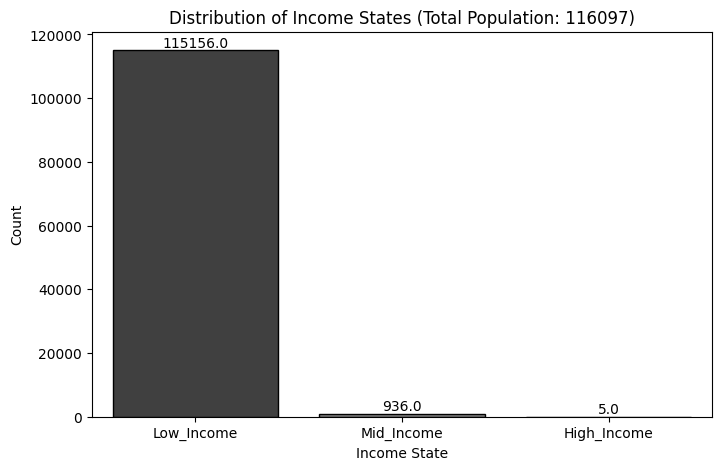

In [18]:
# plot the distribution of IncomeState and add marker for each category in black and white good looking chart
# add legend with total population count
plt.figure(figsize=(8, 5))
sns.countplot(x='IncomeState', data=df, palette='gray', edgecolor='black')
total_count = len(df)
plt.title(f'Distribution of Income States (Total Population: {total_count})')
plt.xlabel('Income State')
plt.ylabel('Count')
for p in plt.gca().patches:
    plt.gca().annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()), 
                       ha='center', va='center', fontsize=10, color='black', xytext=(0, 5), 
                       textcoords='offset points')
plt.show()


# Initial State Vector ($v_0$)

In [19]:
# count proportions of income states in train and test sets
income_counts = df['IncomeState'].value_counts(normalize=True)


In [20]:
v0 = income_counts.reindex(labels).fillna(0).values
v0

array([0.991895, 0.008062, 0.000043])

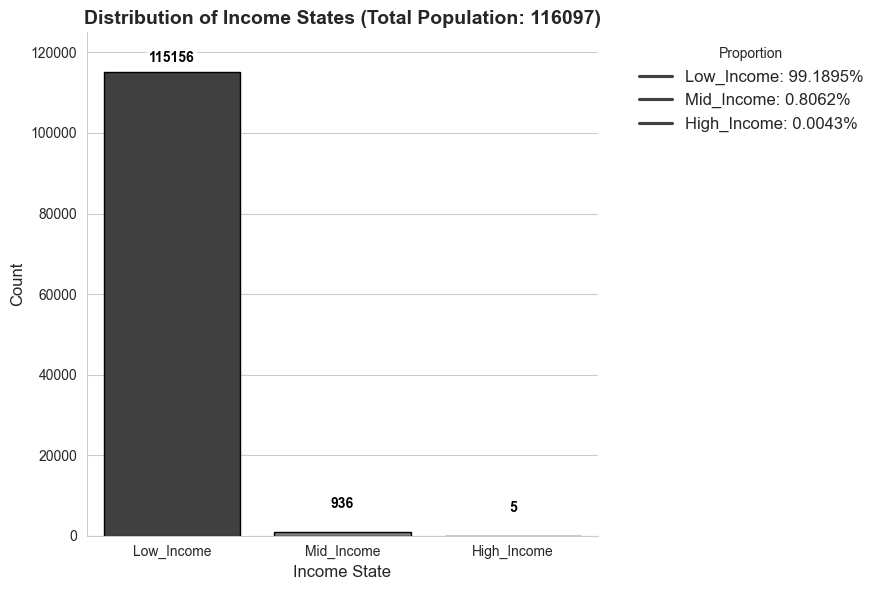

In [21]:

# Calculate counts and proportions
counts = df['IncomeState'].value_counts()
proportions = counts / counts.sum()

sns.set_style("whitegrid")
plt.figure(figsize=(9, 6))

ax = sns.barplot(
    x=counts.index,
    y=counts.values,
    palette="gray",
    edgecolor="black"
)

total_count = len(df)
plt.title(f'Distribution of Income States (Total Population: {total_count})', fontsize=14, weight='bold')
plt.xlabel('Income State', fontsize=12)
plt.ylabel('Count', fontsize=12)

# Annotate bars with counts (cleaner placement)
for i, p in enumerate(ax.patches):
    count = counts.values[i]
    # dynamic offset: higher for small bars
    offset = 5 if count > 1000 else 15
    ax.annotate(
        f'{count}',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom',
        fontsize=10, fontweight='bold', color='black',
        xytext=(0, offset), textcoords='offset points',
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7)
    )

# Legend with proportions
legend_labels = [f'{state}: {prop:.4%}' for state, prop in proportions.items()]
plt.legend(legend_labels, title='Proportion', bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False, fontsize=12)

plt.ylim(0, 125000)  # keep your adjusted scale
sns.despine()
plt.tight_layout()
plt.show()


In [22]:
round(sum(v0))  # Should be 1.0

1

# 1. Baseline Matrix from Prior Literature

In [23]:
# These are your hypotheses. You can change these numbers.
# Each row MUST sum to 1.

# P_baseline: "Sticky" economy, low mobility
# Rows:    From [Low, Med, High]
# Columns: To   [Low, Med, High]
P_baseline = np.array([
    [0.846, 0.154, 0.000],  
    [0.025, 0.950, 0.025],  
    [0.000, 0.103, 0.897]   
])


In [24]:
def generate_intervention_matrix(p_base, k):
    """
    Generates a new transition matrix by applying a policy parameter 'k'.

    Args:
        p_base (np.array): The baseline 3x3 transition matrix.
        k (float): The policy strength parameter (e.g., 0.10 for 10%).

    Returns:
        np.array: The new 3x3 intervention matrix.
    """
    
    # Create a copy to avoid changing the original matrix
    p_new = p_base.copy()

    # --- 1. Apply logic to "From Low" row (Row 0) ---
    # We boost P(Low -> Med)
    new_p_low_med = p_base[0, 1] * (1 + k)
    
    # Update the new P(Low -> Med)
    p_new[0, 1] = new_p_low_med
    # Update P(Low -> Low) to ensure the row still sums to 1
    # P(Low -> High) (p_base[0, 2]) remains unchanged
    p_new[0, 0] = 1 - new_p_low_med - p_base[0, 2]

    # --- 2. Apply logic to "From Medium" row (Row 1) ---
    # We boost upward mobility P(Med -> High)
    new_p_med_high = p_base[1, 2] * (1 + k)
    # We reduce downward mobility P(Med -> Low)
    new_p_med_low = p_base[1, 0] * (1 - k)

    # Update the matrix with these new values
    p_new[1, 2] = new_p_med_high
    p_new[1, 0] = new_p_med_low
    # Update P(Med -> Med) to ensure the row sums to 1
    p_new[1, 1] = 1 - new_p_med_high - new_p_med_low

    # --- 3. "From High" row (Row 2) ---
    # We assume no change for the "From High" row
    # p_new[2, :] = p_base[2, :] (This is already true from the copy)

    return p_new

In [25]:
# Parameters
n_years = 10  # How many years to simulate
total_pop = df.shape[0]
v_abs_0 = v0 * total_pop  # Initial absolute distribution

# --- Use only one matrix (Baseline) ---
P_matrix = P_baseline

# --- Simulation history ---
history = []
v_current_abs = v_abs_0.copy()
history.append(v_current_abs)  # Year 0

for year in range(n_years):
    v_after_mobility = v_current_abs @ P_matrix
    v_current_abs = v_after_mobility
    history.append(v_after_mobility)

# --- Convert to DataFrame ---
df_history_abs = pd.DataFrame(history, columns=labels)
df_history_proportion = df_history_abs.div(df_history_abs.sum(axis=1), axis=0) * 100


In [26]:
def compute_disparity(df_prop, low="Low_Income", mid="Mid_Income"):
    start_low, end_low = df_prop[low].iloc[0], df_prop[low].iloc[-1]
    start_mid, end_mid = df_prop[mid].iloc[0], df_prop[mid].iloc[-1]

    start_d = start_low / (start_mid )
    end_d = end_low / (end_mid)
    change_d = end_d - start_d

    return start_d, end_d, change_d


In [27]:
def population_analysis(df_abs, state_order):
    """
    Minimalist population analysis for a single scenario, enhanced with:
    - Disparity DF output
    - Summary DF output
    - Fastest + slowest growing segment
    - High & Low income share annotations on the percentage plot
    """
    sns.set_style("whitegrid")
    colors = {'Low_Income':'tab:red','Mid_Income':'tab:green','High_Income':'tab:blue'}

    df_abs = df_abs.copy()
    df_abs["Total"] = df_abs.sum(axis=1)
    df_prop = df_abs[state_order].div(df_abs["Total"], axis=0) * 100

    # ---------------------------------------------------------
    # 1. DISPARITY DATAFRAME
    # ---------------------------------------------------------
    disp_start, disp_end, disp_change = compute_disparity(df_prop)

    disparity_df = pd.DataFrame({
        "Metric": ["Start Disparity", "End Disparity", "Change"],
        "Value": [disp_start, disp_end, disp_change]
    })

    print("\n=== Disparity Summary (Low / Mid) ===")
    display(disparity_df)

    years = df_abs.index
    n_periods = len(years) - 1

    # ---------------------------------------------------------
    # 2. SUMMARY TABLE
    # ---------------------------------------------------------
    abs_changes = df_abs.iloc[-1] - df_abs.iloc[0]
    growth = abs_changes / df_abs.iloc[0].replace(0, np.nan) * 100
    cagr = ((df_abs.iloc[-1] / df_abs.iloc[0].replace(0, np.nan)) ** (1 / n_periods) - 1) * 100

    fastest = cagr.drop("Total").idxmax()
    slowest = cagr.drop("Total").idxmin()

    summary_df = pd.DataFrame({
        "Segment": [c.replace("_", " ") for c in state_order + ["Total"]],
        "Start": df_abs.iloc[0][state_order + ["Total"]].round(3),
        "End": df_abs.iloc[-1][state_order + ["Total"]].round(3),
        "Change": abs_changes[state_order + ["Total"]].round(3),
        "Growth %": growth[state_order + ["Total"]].round(2),
        "CAGR %": cagr[state_order + ["Total"]].round(2)
    })

    print("\n=== Population Change Summary ===")
    display(summary_df)

    print(f"Fastest growing segment: {fastest.replace('_',' ')}")
    print(f"Slowest growing segment: {slowest.replace('_',' ')}\n")

    # ---------------------------------------------------------
    # 3. PLOTS
    # ---------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # ----- Absolute Population Plot -----
    for col in state_order:
        axes[0].plot(years, df_abs[col], color=colors[col], linewidth=2,
                     label=f"{col.replace('_',' ')} (CAGR={cagr[col]:.2f}%)")
    axes[0].plot(years, df_abs["Total"], "--", color="black", linewidth=2, label="Total")
    axes[0].set_title("Absolute Population")
    axes[0].set_xlabel("Year")
    axes[0].set_ylabel("Population")
    axes[0].legend()
    axes[0].grid(True, linestyle='--', alpha=0.6)

    # ----- Share Plot -----
    ax = axes[1]
    ax.stackplot(
        df_prop.index, *(df_prop[c] for c in state_order),
        labels=[c.replace("_"," ") for c in state_order],
        colors=[colors[c] for c in state_order], alpha=0.8
    )
    ax.set_title("Population Share (%)")
    ax.set_xlabel("Year")
    ax.set_ylabel("Percentage")
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.6)

    # ----- HIGH/LOW INCOME ANNOTATION -----
    end_year = df_prop.index[-1]
    low_val = df_prop.loc[end_year, state_order[0]]
    high_val = df_prop.loc[end_year, state_order[2]]

    ax.text(end_year, low_val/2, f"{low_val:.1f}%", color='white',
            ha='right', va='center', fontsize=10, fontweight='bold')

    ax.text(end_year, 100 - high_val/2, f"{high_val:.1f}%", color='white',
            ha='right', va='center', fontsize=10, fontweight='bold')

    plt.tight_layout()
    plt.show()

    return disparity_df, summary_df



=== Disparity Summary (Low / Mid) ===


,Metric,Value
0,Start Disparity,123.03
1,End Disparity,0.38
2,Change,-122.65



=== Population Change Summary ===


,Segment,Start,End,Change,Growth %,CAGR %
Low_Income,Low Income,115156.00,29415.01,-85740.99,-74.46,-12.76
Mid_Income,Mid Income,936.00,77684.10,76748.10,8199.58,55.56
High_Income,High Income,5.00,8997.89,8992.89,179857.77,111.60
Total,Total,116097.00,116097.00,-0.00,-0.00,0.00


Fastest growing segment: High Income
Slowest growing segment: Low Income



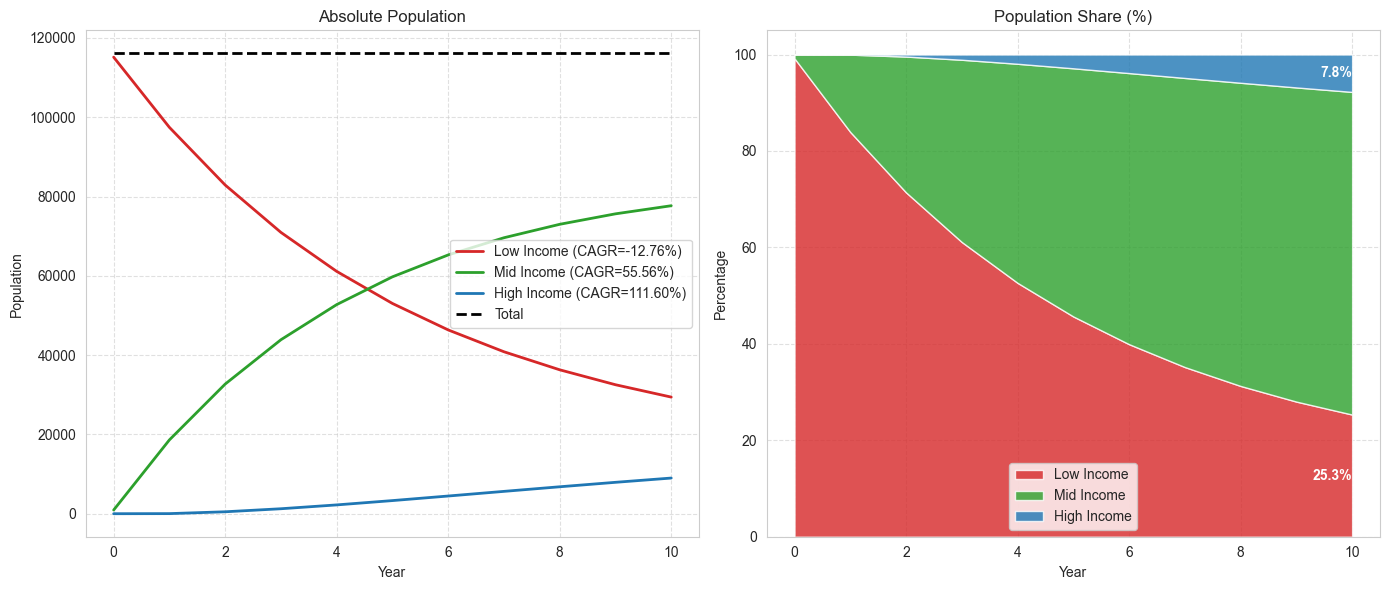

(            Metric   Value
 0  Start Disparity  123.03
 1    End Disparity    0.38
 2           Change -122.65,
                  Segment     Start       End    Change  Growth %  CAGR %
 Low_Income    Low Income 115156.00  29415.01 -85740.99    -74.46  -12.76
 Mid_Income    Mid Income    936.00  77684.10  76748.10   8199.58   55.56
 High_Income  High Income      5.00   8997.89   8992.89 179857.77  111.60
 Total              Total 116097.00 116097.00     -0.00     -0.00    0.00)

In [28]:
population_analysis(df_history_abs, labels)

In [29]:
# Parameters
n_years = 25  # How many years to simulate
total_pop = df.shape[0]
v_abs_0 = v0 * total_pop  # Initial absolute distribution

# --- Use only one matrix (Baseline) ---
P_matrix = P_baseline

# --- Simulation history ---
history = []
v_current_abs = v_abs_0.copy()
history.append(v_current_abs)  # Year 0

for year in range(n_years):
    v_after_mobility = v_current_abs @ P_matrix
    v_current_abs = v_after_mobility
    history.append(v_after_mobility)

# --- Convert to DataFrame ---
df_history_abs = pd.DataFrame(history, columns=labels)
df_history_proportion = df_history_abs.div(df_history_abs.sum(axis=1), axis=0) * 100



=== Disparity Summary (Low / Mid) ===


,Metric,Value
0,Start Disparity,123.03
1,End Disparity,0.18
2,Change,-122.85



=== Population Change Summary ===


,Segment,Start,End,Change,Growth %,CAGR %
Low_Income,Low Income,115156.00,14776.84,-100379.16,-87.17,-7.88
Mid_Income,Mid Income,936.00,83392.90,82456.90,8809.50,19.67
High_Income,High Income,5.00,17927.26,17922.26,358445.21,38.73
Total,Total,116097.00,116097.00,-0.00,-0.00,0.00


Fastest growing segment: High Income
Slowest growing segment: Low Income



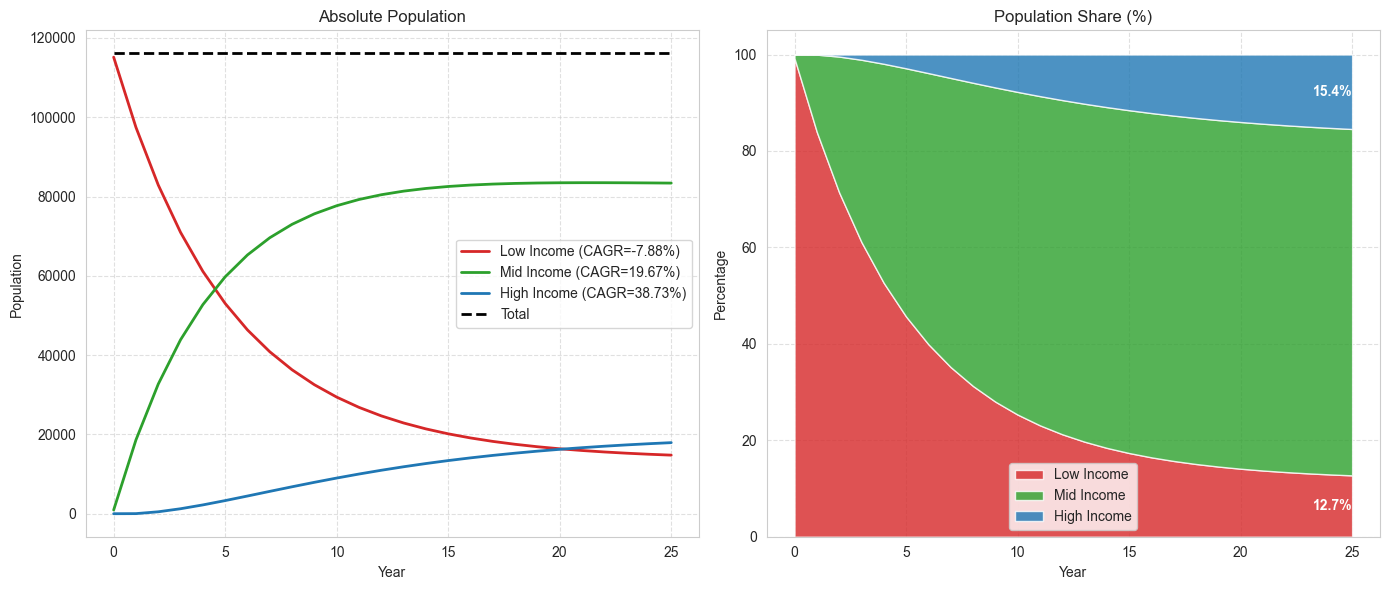

(            Metric   Value
 0  Start Disparity  123.03
 1    End Disparity    0.18
 2           Change -122.85,
                  Segment     Start       End     Change  Growth %  CAGR %
 Low_Income    Low Income 115156.00  14776.84 -100379.16    -87.17   -7.88
 Mid_Income    Mid Income    936.00  83392.90   82456.90   8809.50   19.67
 High_Income  High Income      5.00  17927.26   17922.26 358445.21   38.73
 Total              Total 116097.00 116097.00      -0.00     -0.00    0.00)

In [30]:
population_analysis(df_history_abs, labels)

# 2. Make the Transition Matrix more Realistic 

In [31]:
P_baseline_realistic = np.array([
    [0.98, 0.019, 0.001],  
    [0.025, 0.965, 0.010],  
    [0.001, 0.024, 0.975]   
])
# P_baseline_realistic = P_baseline.copy()

In [32]:
v_abs_0

array([115156.,    936.,      5.])

In [33]:
# Parameters
n_years = 25  # How many years to simulate
total_pop = df.shape[0]
v_abs_0 = v0 * total_pop  # Initial absolute distribution

# --- Growth rates for each income group ---
G_baseline = np.array([
    1,   # 0% net growth for Low
    1,   # 0% net growth for Medium
    1   # 0% net growth for High
])

# --- Use only one matrix (Baseline) ---
P_matrix = P_baseline_realistic  

# --- Simulation history ---
history = []
v_current_abs = v_abs_0.copy()
history.append(v_current_abs)  # Year 0

for year in range(n_years):
    # 1. Mobility
    v_after_mobility = v_current_abs @ P_matrix
    # 2. Growth
    v_next_year_abs = v_after_mobility * G_baseline
    
    history.append(v_next_year_abs)
    v_current_abs = v_next_year_abs

# --- Convert to DataFrame ---
df_history_abs = pd.DataFrame(history, columns=labels)
df_history_proportion = df_history_abs.div(df_history_abs.sum(axis=1), axis=0) * 100



=== Disparity Summary (Low / Mid) ===


,Metric,Value
0,Start Disparity,123.03
1,End Disparity,2.55
2,Change,-120.48



=== Population Change Summary ===


,Segment,Start,End,Change,Growth %,CAGR %
Low_Income,Low Income,115156.00,79445.30,-35710.70,-31.01,-1.47
Mid_Income,Mid Income,936.00,31098.16,30162.16,3222.45,15.04
High_Income,High Income,5.00,5553.55,5548.55,110970.93,32.38
Total,Total,116097.00,116097.00,-0.00,-0.00,0.00


Fastest growing segment: High Income
Slowest growing segment: Low Income



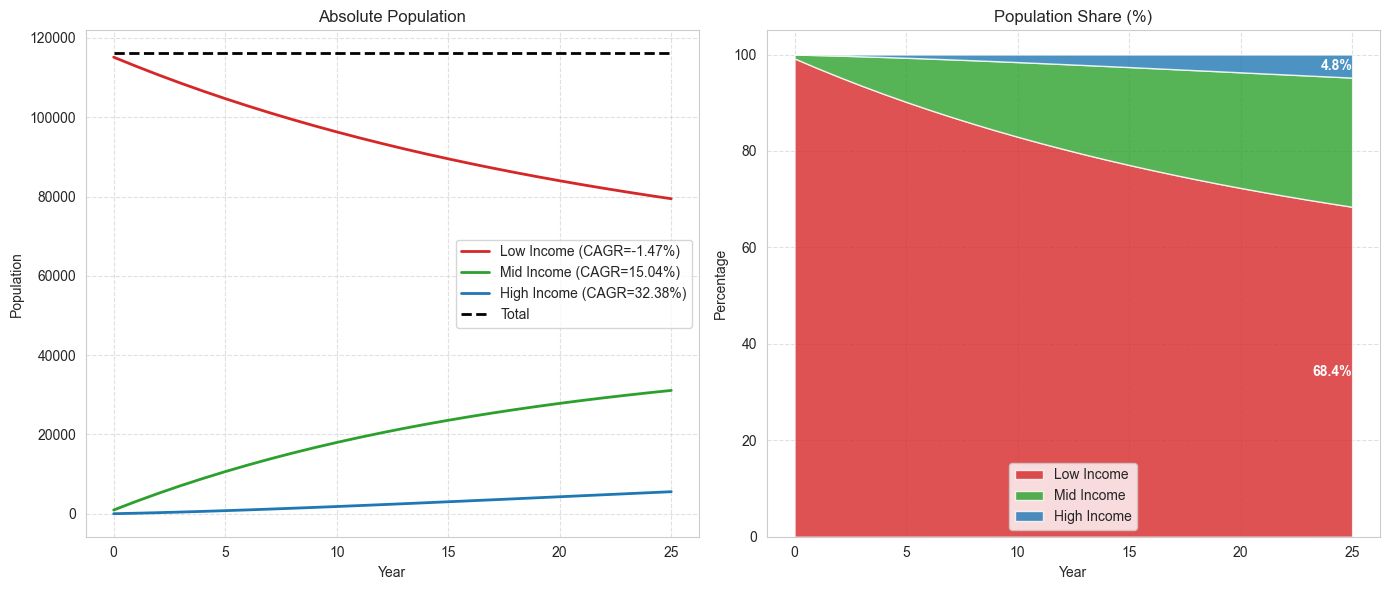

(            Metric   Value
 0  Start Disparity  123.03
 1    End Disparity    2.55
 2           Change -120.48,
                  Segment     Start       End    Change  Growth %  CAGR %
 Low_Income    Low Income 115156.00  79445.30 -35710.70    -31.01   -1.47
 Mid_Income    Mid Income    936.00  31098.16  30162.16   3222.45   15.04
 High_Income  High Income      5.00   5553.55   5548.55 110970.93   32.38
 Total              Total 116097.00 116097.00     -0.00     -0.00    0.00)

In [34]:
population_analysis(df_history_abs, labels)

In [35]:
total_pop

116097

# 3. Added population growth

In [36]:
# read csv file
df_population = pd.read_csv('./content/Population_India_2000_to_2024.csv')
df_population.head()

,Year,Population
0,2000,1057922733
1,2001,1077898575
2,2002,1097600380
3,2003,1116803006
4,2004,1135991513


In [37]:
df_population['PercentChange'] = df_population['Population'].pct_change() * 100
df_population.head()

,Year,Population,PercentChange
0,2000,1057922733,NaN
1,2001,1077898575,1.89
2,2002,1097600380,1.83
3,2003,1116803006,1.75
4,2004,1135991513,1.72


In [38]:
df_population = df_population.dropna(subset=['PercentChange'])
df_population.head()

,Year,Population,PercentChange
1,2001,1077898575,1.89
2,2002,1097600380,1.83
3,2003,1116803006,1.75
4,2004,1135991513,1.72
5,2005,1154676322,1.64


In [39]:
df_population.tail()

,Year,Population,PercentChange
20,2020,1402617695,0.98
21,2021,1414203896,0.83
22,2022,1425423212,0.79
23,2023,1438069596,0.89
24,2024,1450935791,0.89


In [40]:
from scipy.stats import linregress

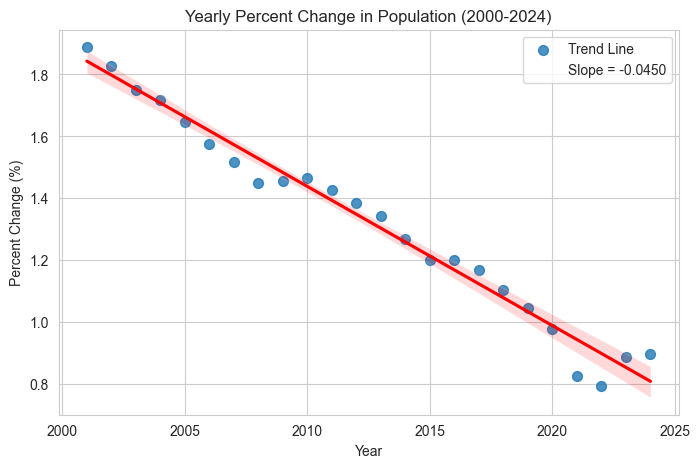

In [41]:
# Perform linear regression
slope, intercept, r_value, p_value, std_err = linregress(df_population['Year'], df_population['PercentChange'])

# Plot with regression line
plt.figure(figsize=(8, 5))
sns.regplot(x='Year', y='PercentChange', data=df_population,
            scatter_kws={'s': 50}, line_kws={'color': 'red'}, label='Trend Line')

# Add slope to legend
plt.plot([], [], ' ', label=f"Slope = {slope:.4f}")
plt.legend(loc='upper right')

plt.title('Yearly Percent Change in Population (2000-2024)')
plt.xlabel('Year')
plt.ylabel('Percent Change (%)')
plt.show()

In [42]:
# Parameters
n_years = 25  # How many years to simulate
total_pop = df.shape[0]
v_abs_0 = v0 * total_pop  # Initial absolute distribution

g_rate = 0.0089
slope = -0.0450

# --- Growth rates for each income group ---
G_baseline_rates = []

# --- Use only one matrix (Baseline) ---
P_matrix = P_baseline_realistic  

# --- Simulation history ---
history = []
v_current_abs = v_abs_0.copy()
history.append(v_current_abs)  # Year 0

for year in range(n_years):
    income_class_growth = np.array([
        1 + g_rate,   # Low
        1 + g_rate,   # Medium
        1 + g_rate    # High
    ])
    G_baseline_rates.append(g_rate*100)
    v_after_growth = v_current_abs * income_class_growth # 1. growth
    v_next_year_abs = v_after_growth @ P_matrix # 2. mobility
    history.append(v_next_year_abs)
    v_current_abs = v_next_year_abs
    g_rate = (1 + slope) * g_rate

# --- Convert to DataFrame ---
df_history_abs = pd.DataFrame(history, columns=labels)
df_history_proportion = df_history_abs.div(df_history_abs.sum(axis=1), axis=0) * 100
df_g_baseline_rates = pd.DataFrame(G_baseline_rates)


=== Disparity Summary (Low / Mid) ===


,Metric,Value
0,Start Disparity,123.03
1,End Disparity,2.55
2,Change,-120.48



=== Population Change Summary ===


,Segment,Start,End,Change,Growth %,CAGR %
Low_Income,Low Income,115156.00,90911.65,-24244.35,-21.05,-0.94
Mid_Income,Mid Income,936.00,35586.56,34650.56,3701.98,15.66
High_Income,High Income,5.00,6355.09,6350.09,127001.81,33.10
Total,Total,116097.00,132853.29,16756.29,14.43,0.54


Fastest growing segment: High Income
Slowest growing segment: Low Income



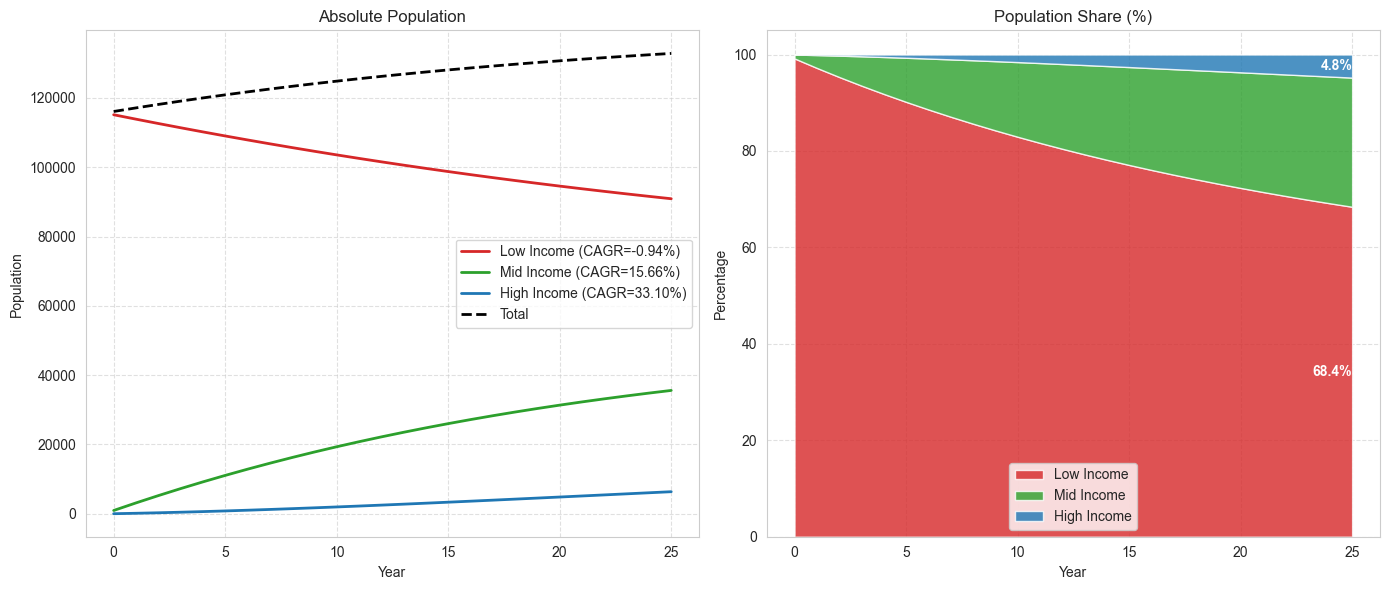

(            Metric   Value
 0  Start Disparity  123.03
 1    End Disparity    2.55
 2           Change -120.48,
                  Segment     Start       End    Change  Growth %  CAGR %
 Low_Income    Low Income 115156.00  90911.65 -24244.35    -21.05   -0.94
 Mid_Income    Mid Income    936.00  35586.56  34650.56   3701.98   15.66
 High_Income  High Income      5.00   6355.09   6350.09 127001.81   33.10
 Total              Total 116097.00 132853.29  16756.29     14.43    0.54)

In [43]:
population_analysis(df_history_abs, labels)

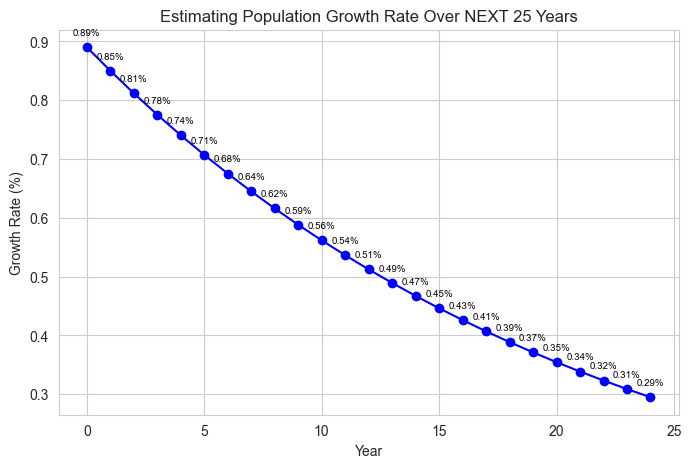

In [44]:
plt.figure(figsize=(8, 5))
plt.plot(df_g_baseline_rates.index, df_g_baseline_rates[0], marker='o', color='blue')

# Annotate each point with its growth rate value
for x, y in zip(df_g_baseline_rates.index, df_g_baseline_rates[0]):
    plt.text(x, y + 0.02, f"{y:.2f}%", ha='center', fontsize=7, color='black')

plt.title('Estimating Population Growth Rate Over NEXT 25 Years')
plt.xlabel('Year')
plt.ylabel('Growth Rate (%)')
plt.show()


# 4. Introduce k-factor (Policy Strength Parameter)

In [45]:

def generate_intervention_matrix(p_base, k):
    """
    Apply policy strength k to a transition matrix.
    
    If k > 0: boost upward transitions (col > row) by (1+k).
    If k < 0: boost downward transitions (row > col) by (1+|k|).
    Then renormalize each row to sum to 1.
    
    Args:
        p_base (np.array): Baseline transition matrix (square, row-stochastic).
        k (float): Policy strength parameter (e.g., 0.10 for +10%).
    
    Returns:
        np.array: Intervention matrix with adjusted probabilities.
    """
    p_new = p_base.copy().astype(float)
    n = p_new.shape[0]
    
    for i in range(n):
        for j in range(n):
            if k > 0 and j > i:   # upward transitions
                p_new[i, j] *= (1 + k)
            elif k < 0 and i > j: # downward transitions
                p_new[i, j] *= (1 + abs(k))
        
        # Renormalize row i
        row_sum = p_new[i, :].sum()
        if row_sum > 0:
            p_new[i, :] /= row_sum
    
    return p_new


In [46]:
# Define our policy strength parameters (the 'k' values)
k_values = {
    'weak': .10,    # 10% boost
    'medium': .25,  # 25% boost
    'strong': .50   # 50% boost
}

# Generate all matrices
intervention_matrices = {}
for name, k in k_values.items():
    matrix_name = f"P_{name}"
    intervention_matrices[matrix_name] = generate_intervention_matrix(P_baseline_realistic, k)

In [47]:
# Print the results
print("--- EMPIRICALLY-ANCHORED BASELINE ---")
print("P_baseline:\n", P_baseline_realistic, "\n")
print("-" * 40)

print("--- INTERVENTION MATRICES ---")
for name, matrix in intervention_matrices.items():
    print(f"{name} (k = {k_values[name.split('_')[1]]}):\n", matrix, "\n")

--- EMPIRICALLY-ANCHORED BASELINE ---
P_baseline:
 [[0.98  0.019 0.001]
 [0.025 0.965 0.01 ]
 [0.001 0.024 0.975]] 

----------------------------------------
--- INTERVENTION MATRICES ---
P_weak (k = 0.1):
 [[0.978044 0.020858 0.001098]
 [0.024975 0.964036 0.010989]
 [0.001    0.024    0.975   ]] 

P_medium (k = 0.25):
 [[0.975124 0.023632 0.001244]
 [0.024938 0.962594 0.012469]
 [0.001    0.024    0.975   ]] 

P_strong (k = 0.5):
 [[0.970297 0.028218 0.001485]
 [0.024876 0.960199 0.014925]
 [0.001    0.024    0.975   ]] 



In [48]:
# Scenario 1: Weak Credit Impact 
P_weak_credit = intervention_matrices['P_weak']

# Scenario 2: Medium Credit Impact 
P_medium_credit = intervention_matrices['P_medium']

# Scenario 3: Strong Credit Impact 
P_strong_credit = intervention_matrices['P_strong']

print("4 simulation matrices (Baseline, Weak, Medium, Strong) defined.")
print("-" * 40)

4 simulation matrices (Baseline, Weak, Medium, Strong) defined.
----------------------------------------


In [49]:
n_years = 25  # How many years to simulate
total_pop = df.shape[0]
v_abs_0 = v0 * total_pop  # Initial absolute distribution

# Initial growth rate and slope
g_rate = 0.0089
slope = -0.0450

matrices = {
    'Baseline': P_baseline_realistic,
    'Weak Impact': P_weak_credit,
    'Medium Impact': P_medium_credit,
    'Strong Impact': P_strong_credit
}

df_history_abs = {}
df_history_proportion = {}
df_g_baseline_rates = {}

# OUTER loop: scenarios
for scenario_name, P_matrix in matrices.items():
    
    current_scenario_history = []
    growth_rate_history = []
    
    v_current_abs = v_abs_0.copy()
    current_scenario_history.append(v_current_abs)  # Year 0
    
    # INNER loop: simulate n_years
    g_t = g_rate
    for year in range(n_years):
        
        # 1. Growth step (uniform across classes)
        income_class_growth = np.array([1 + g_t, 1 + g_t, 1 + g_t])
        v_after_growth = v_current_abs * income_class_growth
        
        # 2. Mobility step
        v_next_year_abs = v_after_growth @ P_matrix
        
        # Save results
        current_scenario_history.append(v_next_year_abs)
        growth_rate_history.append(g_t * 100)  # store in %
        
        # Update for next iteration
        v_current_abs = v_next_year_abs
        g_t = (1 + slope) * g_t
    
    # Convert histories to DataFrames
    df_history_abs[scenario_name] = pd.DataFrame(current_scenario_history, columns=labels)
    df_history_proportion[scenario_name] = df_history_abs[scenario_name].div(
        df_history_abs[scenario_name].sum(axis=1), axis=0
    ) * 100
    df_g_baseline_rates[scenario_name] = pd.DataFrame(growth_rate_history, columns=['GrowthRate'])


In [50]:
def population_analysis_v2(df_history_abs, df_history_proportion, state_order, marker_interval=3):
    """
    df_history_abs, df_history_proportion : dicts keyed by scenario name -> DataFrame (rows=years)
      - df_history_abs[scenario]: absolute counts (columns include state_order + 'Total')
      - df_history_proportion[scenario]: percentages (0-100) for each state in state_order
    state_order : list like ['Low_Income','Mid_Income','High_Income']
    """
    sns.set_style("whitegrid")
    scenarios = list(df_history_abs.keys())
    colors = {'Low_Income':'tab:red','Mid_Income':'tab:green','High_Income':'tab:blue'}

    print("=== Population Change Summary Across Scenarios ===\n")

    fig, axes = plt.subplots(len(scenarios), 2, figsize=(14, 4 * len(scenarios)), sharex=True)
    # normalize axes shape to (n_scenarios, 2)
    if len(scenarios) == 1:
        axes = np.array([axes])
    else:
        axes = np.array(axes)

    for i, scenario in enumerate(scenarios):
        df_abs = df_history_abs[scenario].copy()
        df_prop = df_history_proportion[scenario].copy()

        # --- Disparity metric (assumed available) ---
        try:
            disp_start, disp_end, disp_change = compute_disparity(df_prop)
        except Exception:
            disp_start = disp_end = disp_change = None

        # ensure Total column exists in abs DF
        if 'Total' not in df_abs.columns:
            df_abs['Total'] = df_abs[state_order].sum(axis=1)

        years = df_abs.index
        n_periods = max(len(years) - 1, 1)

        # --- Reporting metrics ---
        abs_changes = df_abs.iloc[-1] - df_abs.iloc[0]
        abs_growth_rates = (abs_changes / df_abs.iloc[0].replace(0, np.nan)) * 100
        cagr = ((df_abs.iloc[-1] / df_abs.iloc[0].replace(0, np.nan)) ** (1.0/n_periods) - 1) * 100

        fastest_segment = cagr.drop('Total').idxmax()
        slowest_segment = cagr.drop('Total').idxmin()

        # --- Build Summary Table ---
        summary_rows = []
        for col in state_order + ['Total']:
            summary_rows.append({
                "Scenario": scenario,
                "Segment": col.replace("_"," "),
                "Start": float(df_abs[col].iloc[0]),
                "End": float(df_abs[col].iloc[-1]),
                "Change": float(abs_changes[col]),
                "Growth (%)": float(abs_growth_rates[col]) if pd.notna(abs_growth_rates[col]) else None,
                "CAGR (%)": float(cagr[col]) if pd.notna(cagr[col]) else None
            })

        # append disparity rows if available
        if disp_start is not None:
            summary_rows.append({
                "Scenario": scenario,
                "Segment": "Disparity (Low/Mid)",
                "Start": disp_start,
                "End": disp_end,
                "Change": disp_change,
                "Growth (%)": None,
                "CAGR (%)": None
            })

        summary_df = pd.DataFrame(summary_rows)
        display(summary_df)

        print(f"Fastest growing segment: {fastest_segment.replace('_',' ')}")
        print(f"Slowest growing segment: {slowest_segment.replace('_',' ')}\n")

        # --- Absolute growth plot (left) ---
        ax1 = axes[i, 0]
        for col in state_order:
            values = df_abs[col]
            ax1.plot(years, values, color=colors.get(col, None), linewidth=2,
                     label=f"{col.replace('_',' ')} | CAGR={cagr[col]:.2f}%")
        ax1.plot(years, df_abs['Total'], linestyle='--', color='black', linewidth=2, label='Total')
        ax1.set_title(f"{scenario}: Absolute Population Growth")
        ax1.set_ylabel("Population")
        ax1.legend(fontsize=9)
        ax1.grid(True, linestyle='--', alpha=0.7)

        # --- Proportion stacked area plot (right) ---
        ax2 = axes[i, 1]
        # ensure df_prop columns are in the requested order
        prop_arrays = [df_prop[col].values for col in state_order]
        ax2.stackplot(df_prop.index, *prop_arrays,
                      labels=[s.replace("_"," ") for s in state_order],
                      colors=[colors.get(c) for c in state_order], alpha=0.8)

        # Compute final-year positions for labels (assumes df_prop is in percent: 0-100)
        last_year = df_prop.index[-1]
        y_low = float(df_prop[state_order[0]].iloc[-1])
        y_mid = float(df_prop[state_order[1]].iloc[-1])
        y_high = float(df_prop[state_order[2]].iloc[-1])

        # Low label sits at bottom of its area (use a small offset upward)
        low_pos = y_low / 2.0  # center of the low band
        # High label should be placed near the top of the high band:
        top_of_high = y_low + y_mid + y_high
        high_pos = (y_low + y_mid) + (y_high / 2.0)  # center of the high band

        # choose horizontal position slightly left of the right edge to avoid clipping
        x_pos = last_year if np.issubdtype(type(last_year), np.number) else df_prop.index.tolist()[-1]

        ax2.text(x_pos, low_pos, f"{y_low:.1f}%", color="white",
                 fontsize=9, va='center', ha='right' if isinstance(x_pos, (int,float)) else 'right')
        ax2.text(x_pos, high_pos, f"{y_high:.1f}%", color="white",
                 fontsize=9, va='center', ha='right')

        ax2.set_title(f"{scenario}: Population Share (%)")
        ax2.set_ylabel("Percentage (%)")
        ax2.set_xlim(df_prop.index.min(), df_prop.index.max())
        ax2.legend(loc='upper left')
        ax2.grid(True, linestyle='--', alpha=0.7)

    # common x-labels
    axes[-1, 0].set_xlabel("Year")
    axes[-1, 1].set_xlabel("Year")
    plt.tight_layout()
    plt.show()


=== Population Change Summary Across Scenarios ===



,Scenario,Segment,Start,End,Change,Growth (%),CAGR (%)
0,Baseline,Low Income,115156.00,90911.65,-24244.35,-21.05,-0.94
1,Baseline,Mid Income,936.00,35586.56,34650.56,3701.98,15.66
2,Baseline,High Income,5.00,6355.09,6350.09,127001.81,33.10
3,Baseline,Total,116097.00,132853.29,16756.29,14.43,0.54
4,Baseline,Disparity (Low/Mid),123.03,2.55,-120.48,NaN,NaN


Fastest growing segment: High Income
Slowest growing segment: Low Income



,Scenario,Segment,Start,End,Change,Growth (%),CAGR (%)
0,Weak Impact,Low Income,115156.00,87674.97,-27481.03,-23.86,-1.08
1,Weak Impact,Mid Income,936.00,37890.28,36954.28,3948.11,15.96
2,Weak Impact,High Income,5.00,7288.04,7283.04,145660.81,33.83
3,Weak Impact,Total,116097.00,132853.29,16756.29,14.43,0.54
4,Weak Impact,Disparity (Low/Mid),123.03,2.31,-120.72,NaN,NaN


Fastest growing segment: High Income
Slowest growing segment: Low Income



,Scenario,Segment,Start,End,Change,Growth (%),CAGR (%)
0,Medium Impact,Low Income,115156.00,83069.70,-32086.30,-27.86,-1.30
1,Medium Impact,Mid Income,936.00,41028.56,40092.56,4283.39,16.32
2,Medium Impact,High Income,5.00,8755.03,8750.03,175000.58,34.81
3,Medium Impact,Total,116097.00,132853.29,16756.29,14.43,0.54
4,Medium Impact,Disparity (Low/Mid),123.03,2.02,-121.01,NaN,NaN


Fastest growing segment: High Income
Slowest growing segment: Low Income



,Scenario,Segment,Start,End,Change,Growth (%),CAGR (%)
0,Strong Impact,Low Income,115156.00,76010.27,-39145.73,-33.99,-1.65
1,Strong Impact,Mid Income,936.00,45491.12,44555.12,4760.16,16.81
2,Strong Impact,High Income,5.00,11351.91,11346.91,226938.11,36.22
3,Strong Impact,Total,116097.00,132853.29,16756.29,14.43,0.54
4,Strong Impact,Disparity (Low/Mid),123.03,1.67,-121.36,NaN,NaN


Fastest growing segment: High Income
Slowest growing segment: Low Income



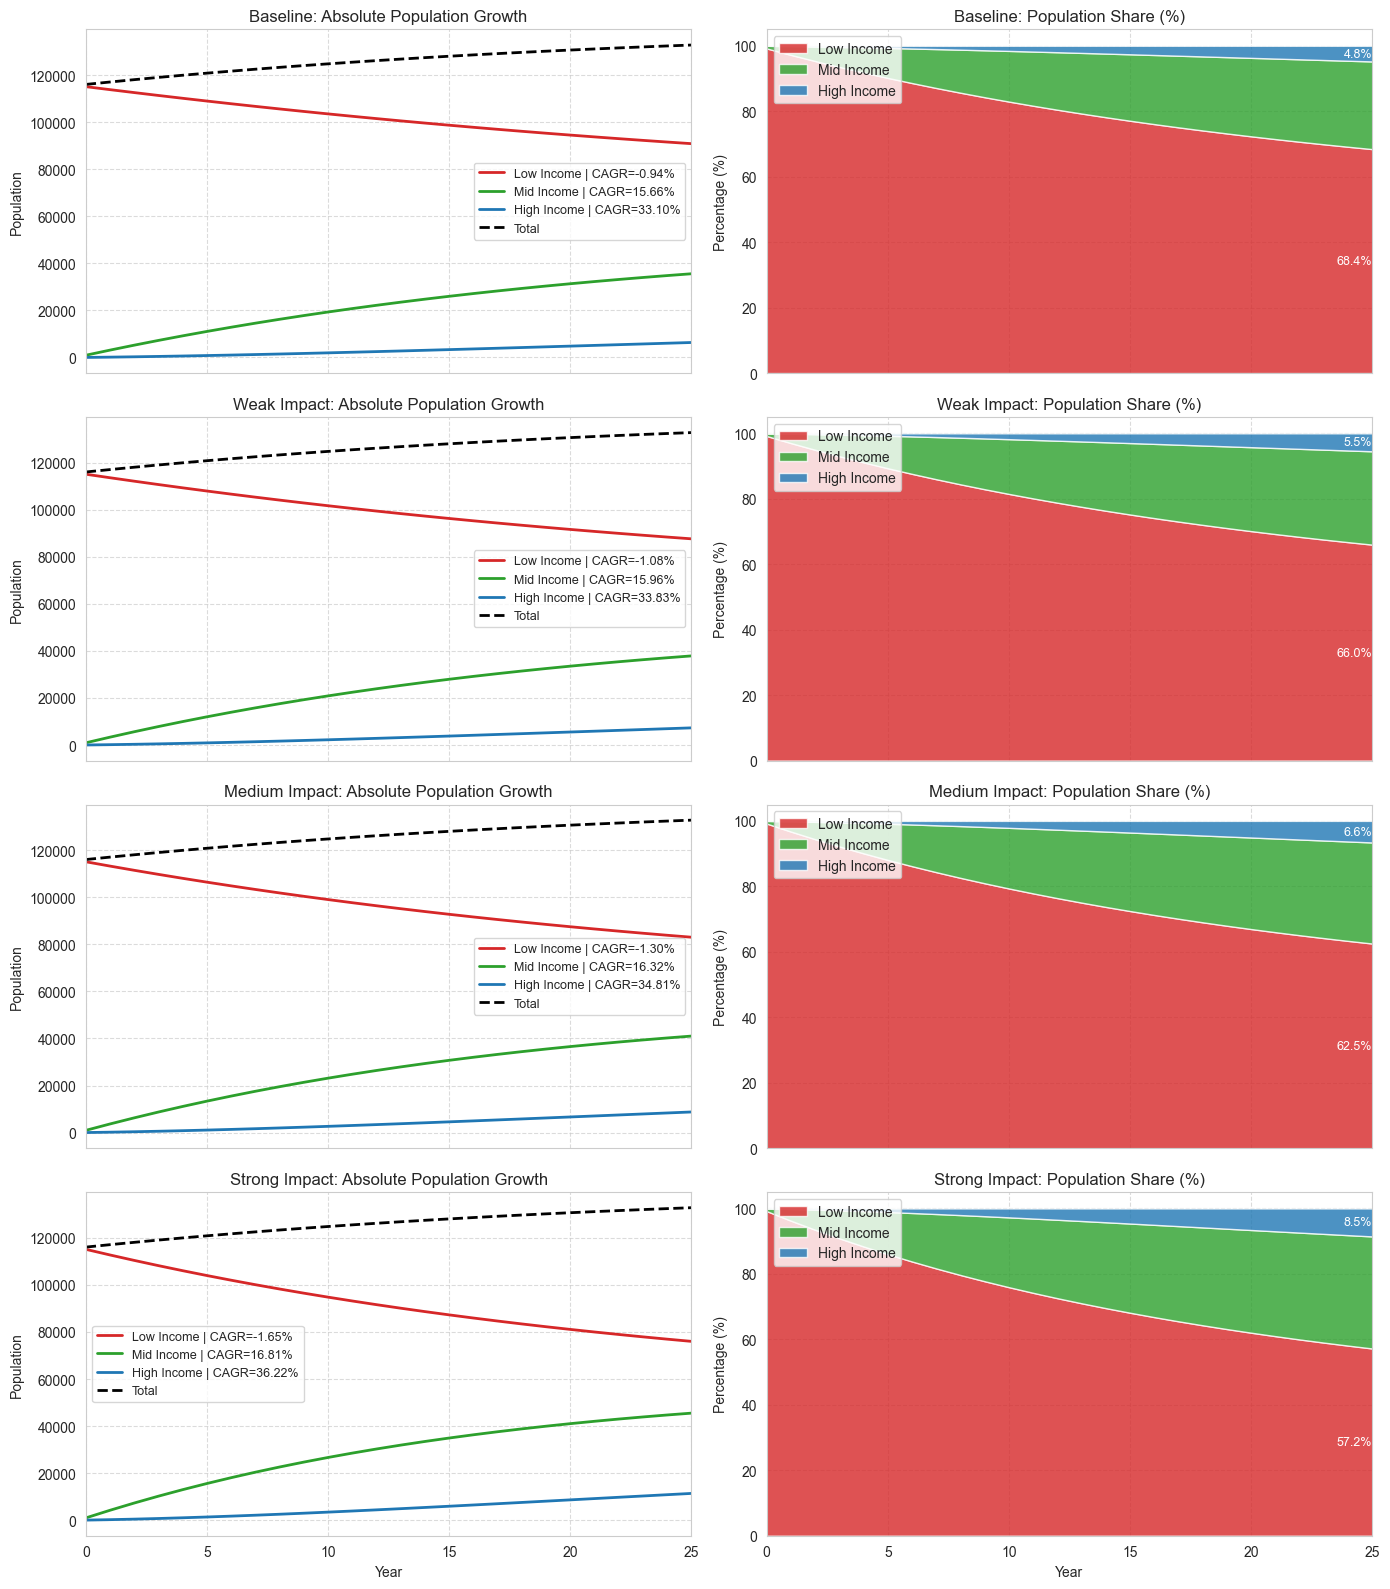

In [51]:
population_analysis_v2(df_history_abs, df_history_proportion, labels, marker_interval=2)